# Heart Disease Prediction Using Machine Learning

## 1. Introduction

This project focuses on predicting heart disease status using machine learning. We will explore patient health data, prepare the dataset, train and compare eight classification models, and evaluate their performance.

We will also investigate feature reduction techniques such as PCA and LDA, examine important features, and develop an educational prototype.

## 2. Dataset Information

Dataset: Heart Failure Prediction Dataset

Source: Kaggle (fedesoriano)

Records: 918

Input Features: 11

Target Variable: HeartDisease (0 = No, 1 = Yes)

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Exploratory Data Analysis

### 3.1 Dataset Overview

We will examine the structure of the dataset, including the number of records, features, and data types.

In [49]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (918, 12)

Column names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


### 3.2 Descriptive Statistics

We will examine the numerical features to understand their distributions and identify any unusual values.

In [50]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


### 3.3 Data Quality Checks

We will check for missing values and investigate suspicious zero values in the dataset.

In [55]:
print("Missing values:")
print(df.isnull().sum())

print("\nZero cholesterol values:", (df["Cholesterol"] == 0).sum())
print("Zero resting blood pressure values:", (df["RestingBP"] == 0).sum())

Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Zero cholesterol values: 172
Zero resting blood pressure values: 1


**Data Quality Findings**

The dataset contains no missing values detected by pandas. However, 172 records have cholesterol values of zero, and one record has a resting blood pressure value of zero. These values may represent missing or incorrectly recorded measurements. We will address them during preprocessing while taking precautions to avoid data leakage.

### 3.4 Target Variable Distribution

We will examine the number and percentage of patients in each heart disease category to understand the class distribution.

In [57]:
print("Heart Disease Counst:")
print(df["HeartDisease"].value_counts())

print("\nHeart Disease Percentages:")
print(df["HeartDisease"].value_counts(normalize=True)*100)

Heart Disease Counst:
HeartDisease
1    508
0    410
Name: count, dtype: int64

Heart Disease Percentages:
HeartDisease
1    55.337691
0    44.662309
Name: proportion, dtype: float64


**Target Distribution Findings**

The dataset contains 508 patients with heart disease (55.34%) and 410 patients without heart disease (44.66%). The two classes are relatively balanced, which is useful for our classification task. We will consider this distribution when splitting the data and evaluating our models.

### 3.5 Data Visualization

We will visualize the distribution of heart disease status and other important features to better understand the dataset.

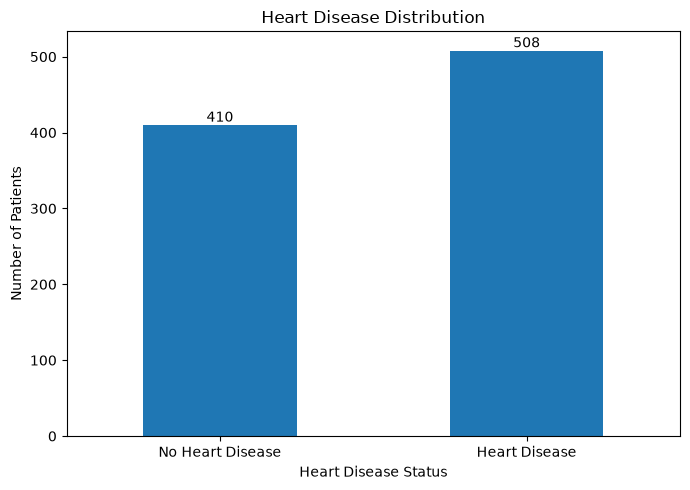

In [58]:
counts = df["HeartDisease"].value_counts().sort_index()

ax = counts.plot(kind="bar", figsize=(7,5))

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease Status")
plt.ylabel("Number of Patients")
plt.xticks([0,1], ["No Heart Disease", "Heart Disease"], rotation=0)

ax.bar_label(ax.containers[0])

plt.tight_layout()
plt.show()

#### Age Distribution

We will examine the age distribution of patients to understand which age groups are most represented in the dataset.

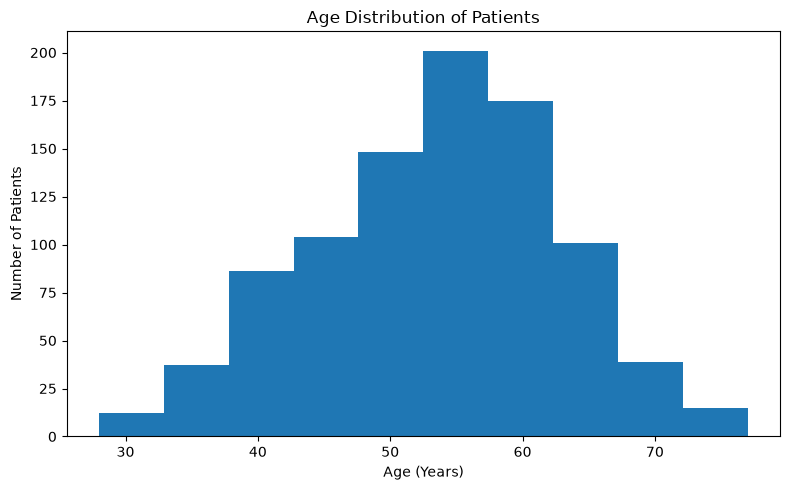

In [59]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=10)

plt.title("Age Distribution of Patients")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

### 3.6 Feature Relationships

We will compare selected nuumericl features between patients with and without heart disease to identify possible patterns in the dataset.

In [61]:
df.groupby("HeartDisease")[["Age", "MaxHR"]].mean().round(2)

,Age,MaxHR
HeartDisease,,
0,50.55,148.15
1,55.90,127.66


**Feature Relationship Findings**

From the results, we can see that patients with heart disease have an average age of 55.90 years, while patients without heart disease have an average age of 50.55 years. We also found that patients with heart disease have a lower average maximum heart rate of 127.66 compared to 148.15 for patients without heart disease. This shows that age and maximum heart rate may be useful features for our machine learning models.